# Evaluate TCIA Dataset

In [1]:
import os, torch

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["KERAS_BACKEND"] = "torch"

# initialize dataset parameters
data_dir = os.path.normpath('/home/qhe2/Documents/Datasets/TCIA/processed/')
idx = 0

# initialize model parameters
device = torch.device('cuda')
model_path = os.path.normpath('models/stanford_v0.0.1.h5')

## Load Dataset

In [2]:
from data import load

_, dataset = load(data_dir, preprocessed=True, return_path=True)

/home/qhe2/Applications/miniconda3/envs/Comp2Comp/lib/python3.11/site-packages/monai/utils/module.py:399: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  pkg = __import__(module)  # top level module
/home/qhe2/Applications/miniconda3/envs/Comp2Comp/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1784314731.947275 3996685 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
len(dataset)

83

In [4]:
from typing import cast

x, y, path = cast(tuple[torch.Tensor, torch.Tensor, str], dataset[idx])
x = x.unsqueeze(0)
y = y.unsqueeze(0)
path

'/home/qhe2/Documents/Datasets/TCIA/processed/0522c0014'

In [5]:
x.shape, y.shape

(torch.Size([1, 512, 512, 3]), torch.Size([1, 512, 512]))

In [6]:
x.max(), x.min(), y.max(), y.min()

(tensor(1300.), tensor(-500.), tensor(1), tensor(0))

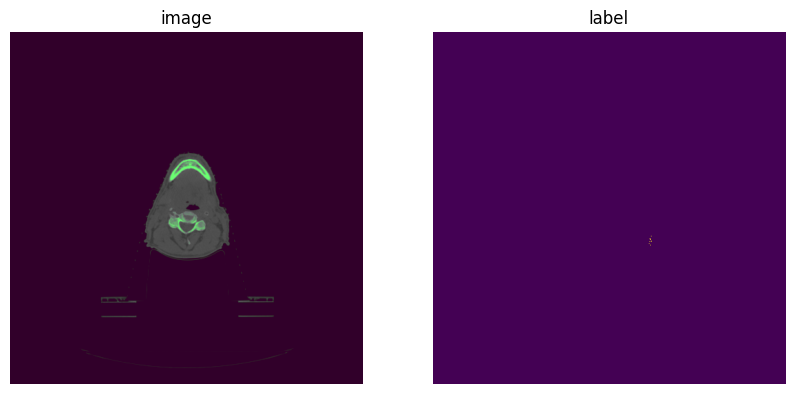

In [7]:
import numpy as np
from matplotlib import pyplot as plt

x_np = x[0].permute(1, 0, 2).detach().cpu().numpy()
x_np = (x_np - x_np.min()) / (x_np.max() - x_np.min())
y_np = y[0].permute(1, 0).detach().cpu().numpy()

# prepare label display
is_scalar_label = np.ndim(y_np) == 0 or (y_np.ndim == 1 and y_np.size == 1)

if is_scalar_label:
    plt.figure(figsize=(6,6))
    plt.imshow(x_np, cmap='gray' if x_np.ndim == 2 else None)
    plt.title(f"label: {int(np.squeeze(y_np))}")
    plt.axis('off')
else:
    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    plt.imshow(x_np, cmap='gray' if x_np.ndim == 2 else None)
    plt.title('image')
    plt.axis('off')

    plt.subplot(1,2,2)
    # convert label channels if needed
    if y_np.ndim == 3 and y_np.shape[0] in (1,3):
        lbl = y_np.squeeze(0) if y_np.shape[0] == 1 else np.transpose(y_np, (1,2,0))
    else:
        lbl = y_np
    plt.imshow(lbl)
    plt.title('label')
    plt.axis('off')

plt.show()

## Load Model

In [8]:
import keras

print("keras backend:", keras.backend.backend())

keras backend: torch


In [9]:
from comp2comp.finetune.metrics import SparseMeanDice
from comp2comp.finetune.optim import LayerwiseAdam

In [10]:
import keras
from typing import cast

model = cast(keras.Model, keras.models.load_model(model_path))

## Predict

In [11]:
pred: torch.Tensor = model(x)

In [12]:
pred = pred.argmax(dim=-1)

In [13]:
pred.shape

torch.Size([1, 512, 512])

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

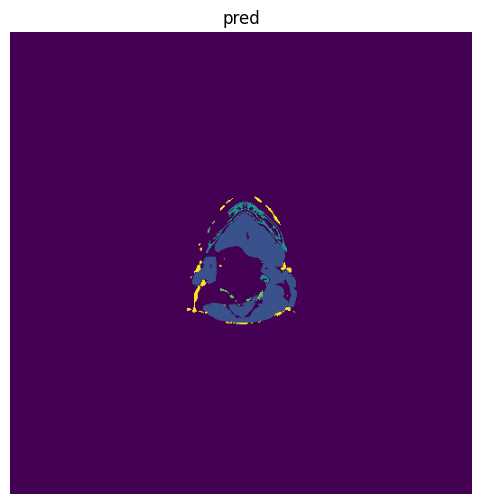

In [14]:
pred_np = pred[0].permute(1, 0).cpu().detach().numpy()

plt.figure(figsize=(6,6))
# convert label channels if needed
if pred_np.ndim == 3 and pred_np.shape[0] in (1,3):
    lbl = pred_np.squeeze(0) if pred_np.shape[0] == 1 else np.transpose(pred_np, (1,2,0))
else:
    lbl = pred_np
plt.imshow(lbl)
plt.title('pred')
plt.axis('off')

In [15]:
from torch.utils.data import DataLoader, Sampler

data_loader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=False,
    num_workers=min(4, os.cpu_count() or 1),
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
)

In [16]:
model.evaluate(data_loader, verbose=1, return_dict=True)

AttributeError: 'Functional' object has no attribute 'optimizer'